In [56]:
import numpy as np
import FBA_ode

Nnenna Model

In [57]:
# constants
k = np.zeros(34)  # Defining the array, k, that will house reaction rates

# Rxns (Cytosolic)

k[0] = 1e-2  # Permeability constant (plasma membrane) (cm/s)
k[1] = 24e-7  # Intracellular peroxide production (M/s)
k[2] = 2.1e7  # GPx_red reacting with H2O2in (M-1*s-1)
k[3] = 4e4  # GPx_ox reacting with GSH (M-1*s-1)
k[4] = 1e7  # GPx-SSG reacting with GSH (M-1*s-1)
k[5] = 3.4e7  # Catalase reacts with H2O2 inside peroxisome (M-1*s-1)
k[6] = 5.7e-5  # Km of NADP+ (M)
k[7] = 4e7  # Peroxiredoxin is oxidized by H2O2 (M-1*s-1)
k[8] = 7.2e4  # Oxidized peroxiredoxin is over-oxidized by H2O2 (M-1*s-1)
k[9] = 3e-3  # Reduction of overoxidized Prx by Srx enzyme (s-1)
k[10] = 15  # Self-catalyzed disulfide formation of Prx-SS from Prx-SOH (s-1)
k[11] = 2.1e6  # Peroxiredoxin is reduced by Thioredoxin (M-1*s-1)
k[12] = 7.4e-05  # Auto-oxidation of GSH (s-1)
k[13] = 1e4  # Protein monothiol oxidized by H2O2 (M-1*s-1)
k[14] = 1.2e5  # Oxidized Protein monothiol glutathionylated by GSH (M-1*s-1)
k[15] = 9.1e4  # Grx-SH de-glutathionylates Protein-SSG (M-1*s-1)
k[16] = 3.7e4  # GSH de-glutathionylates Grx-SSG (M-1*s-1)
k[17] = 5e5  # Protein dithiol oxidized by H2O2 (M-1*s-1)
k[18] = 1e5  # Protein disulfide reduced by Trx (M-1*s-1)
k[19] = 3.2e6  # GSSG reduced by GR (M-1*s-1)
k[20] = 2e7  # Oxidized Thioredoxin reduced by TrxR (M-1*s-1)
k[21] = 3.75e-04  # Production of NADPH by G6P-DH (M/s)
k[22] = 3e-3  # Permeability constant (peroxisomal membrane) (cm/s)
k[23] = 4.1e-7  # GSH synthesis (M/s)
k[24] = 1.2e-8  # GSSG efflux (M/s)
k[25] = 1.2e-7  # GSH + GSSG efflux (M/s)
k[26] = 7.45e-10  # Trx_SH efflux (M/s)
k[27] = 6.97e-10  # Trx_SH synthesis (M/s)
k[28] = 0#1e-5 # nox generation of superoxide ()    #Banfi B. et al, JBC 2002
k[29] = 0#4e9 # superoxide dismutase reduction and oxidation by superoxide (M-1*s-1), from Fee J.A. & Bull C. The journal of biological chemistry 1986
k[30] = 0 # intracellular superoxide production (M/s)
k[31] = 0 # nox h2o2 production (M/s)
k[32] = 8.87e-8 # nox 2 (M/s?)
k[33] = 8.87e-8 # nox 5 production rate (M/s)  

print(k)

[1.00e-02 2.40e-06 2.10e+07 4.00e+04 1.00e+07 3.40e+07 5.70e-05 4.00e+07
 7.20e+04 3.00e-03 1.50e+01 2.10e+06 7.40e-05 1.00e+04 1.20e+05 9.10e+04
 3.70e+04 5.00e+05 1.00e+05 3.20e+06 2.00e+07 3.75e-04 3.00e-03 4.10e-07
 1.20e-08 1.20e-07 7.45e-10 6.97e-10 0.00e+00 0.00e+00 0.00e+00 0.00e+00
 8.87e-08 8.87e-08]


In [58]:
# initial conditions

x0 = np.zeros(32)  # Defining the array, x0, that will house initial concentrations
# Cytoplasm
x0[0] = 0  # H2O2media 
x0[1] = 1.0e-9  # H2O2cytosol

x0[2] = 5e-5  # GPXr 
x0[3] = 1e-14  # GPXo 
x0[4] = 1e-14  # GPX-SG 

x0[5] = 3.68e-4  # GSH 
x0[6] = 1.78e-6  # GSSG 

x0[7] = 9e-7  # Catalase 
x0[8] = 1.0e-10  # H2O2peroxisome 

x0[9] = 1.92e-5  # Prx-SH  
x0[10] = 1e-14  # Prx-SOH 
x0[11] = 1e-14  # Prx-SOOH 
x0[12] = x0[9] * (0.5 / 100)  # Prx-SS 

x0[13] = 4.27e-7  # Trx1-SH 
x0[14] = 7.54e-8  # Trx1-SS 

x0[15] = 1.22e-4  # Pr-SH 
x0[16] = x0[15] * (0.5 / 100)  # Pr-SOH
x0[17] = x0[15] * (0.5 / 100)  # Pr-SSG 

x0[18] = 1.20e-6  # Grx-SH 
x0[19] = x0[18] * (0.5 / 100)  # Grx-SSG 

x0[20] = 1.09e-3  # Pr-(SH)2  
x0[21] = x0[20] * (0.5 / 100)  # Pr-SS

x0[22] = 3.0e-5  # NADPH 
x0[23] = 3.0e-7  # NADP+

x0[24] = 0 # superoxide media
x0[25] = 0#1e-9 # superoxide cytosol

x0[26] = 0 # superoxide dismutase reduced
x0[27] = 0 # superoxide dismutase oxidized

x0[28] = 1e-9 # steady state h2o2 intracellular

x0[29] = 0 # calcium intracellular
x0[30] = 0 # calcium extracellular
x0[31] = 100e-6 # calcium ER [M]

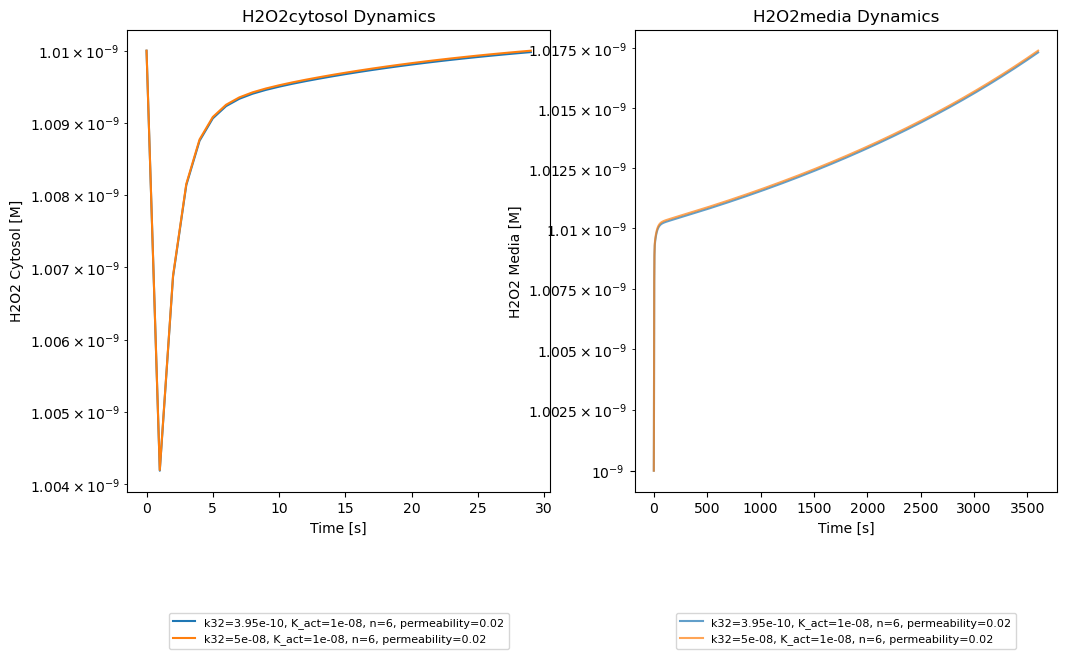

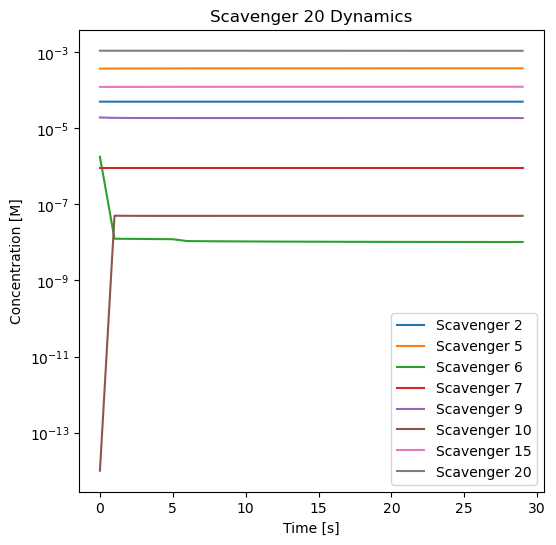

In [61]:
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import fsolve

# Define the parameterized model (copy your full ODEs here)
def model_noref_param(x, t, k, x0, k32, K_act, n, h_baseline, permeability_coefficient):

    # def nox_h2o2_rate(x, Vmax, K_act, n, h_baseline):
    #     h = max(x[1] - h_baseline, 0.0)
    #     f = (h**n) / (K_act**n + h**n) if h > 0 else 0.0
    #     return Vmax * f
    def nox_h2o2_rate(x, Vmax, K_act, n, h_baseline):
        f = (x[1]**n) / (K_act**n + x[1]**n) if x[1] > 0 else 0.0
        return Vmax * f
    
    dxdt = np.zeros_like(x)
    k_decay = 1e-4
    
    k31_hill = nox_h2o2_rate(x, Vmax=k32, K_act=K_act, n=n, h_baseline=h_baseline)
    nox2 = nox_h2o2_rate(x, Vmax=k32, K_act=K_act, n=6, h_baseline=1e-9)                     #nox2
    k[0] = permeability_coefficient

    # 2D sink (add this)
    D_2d = 1.8e-5   # [cm^2/s], adjust as needed
    R_2d = 0.1      # [cm], adjust as needed
    sink_2d = - (2 * np.pi * D_2d / R_2d) * x[0]

    dxdt[0] = (k[0] * (x[1] - x[0]) * 10e-3 * 5.3e-6 * (1e9)) + nox2 - k_decay * x[0]#+ sink_2d
    # --- Copy the rest of your ODEs from model_noref here ---

    dxdt[1] = (((k[0] * x[0] * 10e-3 * 5.3e-6) / (1.15e-12))
               - ((k[0] * x[1] * 10e-3 * 5.3e-6) / (1.15e-12))
               - 2 * (k[22] * x[1] * 10e-3 * 2.98e-9) / (1.53e-14)              # peroxisomal H2O2     
               - k[2] * x[2] * x[1]                             # GPx reduction of H2O2
               - k[5] * x[7] * x[1]                                   # catalase reaction
               - k[7] * x[9] * x[1]                                   # peroxiredoxin oxidation
               - k[8] * x[10] * x[1]                                  # overoxidized peroxiredoxin
               - k[13] * x[15] * x[1]                                 # Protein monothiol oxidation
               - k[17] * x[20] * x[1]                                 # Protein dithiol oxidation
               + k[1]                                                          # intracellular peroxide production
               + k[29] * x[25] * x[27])                                      # superoxide dismutase reduction and oxidation by superoxide

    dxdt[2] = (- k[2] * x[2] * x[1]
               + k[4] * x[4] * x[5])
    
    dxdt[3] = k[2] * x[2] * x[1] - k[3] * x[3] * x[5]
    dxdt[4] = k[3] * x[3] * x[5] - k[4] * x[4] * x[5]
    dxdt[5] = (- k[3] * x[3] * x[5]
               - k[4] * x[4] * x[5]
               - 2 * k[12] * x[5]
               - k[14] * x[16] * x[5]
               - k[16] * x[16] * x[5]
               + 2 * k[19] * x[6] * x[22]
               + k[23] 
               - k[25])
    dxdt[6] = (k[4] * x[4] * x[5] + k[12] * x[5] +
               k[16] * x[19] * x[5] - k[19] * x[6] * x[22] 
               - k[24] * x[6] / x0[6]
               - k[25] * x[6] / x0[6]
               )
    dxdt[7] = 0
    dxdt[8] = (k[22] * x[1] * 10e-3 * 2.98e-9) / (1.53e-14) - k[5] * x[7] * x[8]
    dxdt[9] = - k[7] * x[9] * x[1] + k[11] * x[12] * x[13]
    dxdt[10] = (k[7] * x[9] * x[1] - k[8] * x[10] * x[1] +
                k[9] * x[11] - k[10] * x[10])
    dxdt[11] = k[8] * x[10] * x[1] - k[9] * x[11]
    dxdt[12] = k[10] * x[10] - k[11] * x[12] * x[13]
    dxdt[13] = (- k[11] * x[12] * x[13] 
                - k[18] * x[21] * x[13] 
                + k[20] * x[14] * x[22] 
                - k[26] 
                + k[27])
    dxdt[14] = (k[11] * x[12] * x[13] + k[18] * x[21] * x[13] -
                k[20] * x[14] * x[22])

    dxdt[15] = (- k[13] * x[15] * (x[1])
                + k[15] * x[18] * (x[17]))

    dxdt[16] = k[13] * x[15] * x[1] - k[14] * x[16] * x[5]
    dxdt[17] = k[14] * x[16] * x[5] - k[15] * x[18] * x[17]
    dxdt[18] = k[16] * x[19] * x[5] - k[15] * x[18] * x[17]
    
    dxdt[19] = (k[15] * x[18] * x[17] 
                - k[16] * x[19] * x[5])
    
    dxdt[20] = - k[17] * x[20] * x[1] + k[18] * x[21] * x[13]
    dxdt[21] = k[17] * x[20] * x[1] - k[18] * x[21] * x[13]

    #NADPH
    dxdt[22] = (- k[19] * x[6] * x[22] 
                - k[20] * x[14] * x[22] 
                #- k[28] * x[22]                                         # nox generation of superoxide
                + k[21] * x[23] / (k[6] + x[23]))
    #NADP+
    dxdt[23] = (k[19] * x[6] * x[22] 
                + k[20] * x[14] * x[22] 
                #+ k[28] * x[22]                                         # nox generation of superoxide and nadp+
                - k[21] * x[23] / (k[6] + x[23]))

    dxdt[24] = (k[0] * (x[25] - x[24]) * 10e-3 * 1.02e-5 * (1e9)               # superoxide media
                + k[28] * x[22])
    
    dxdt[25] = (((k[0] * x[24] * 10e-3 * 1.02e-5) / (9.16e-13))                 # superoxide cytosol
               - ((k[0] * x[25] * 10e-3 * 1.02e-5) / (9.16e-13))
               - k[29] * x[25] * x[26]
               - k[29] * x[25] * x[27]
               + k[30])
    
    dxdt[26] = (k[29] * x[25] * x[27] 
                - k[29] * x[25] * x[26])

    dxdt[27] = (k[29] * x[25] * x[26] 
                - k[29] * x[25] * x[27])
    
    #dxdt[28] = 0#(((k[0] * x[29] * 10e-3 * 1.02e-5) / (9.16e-13))               # calcium cytosol
               #- ((k[0] * x[28] * 10e-3 * 1.02e-5) / (9.16e-13)))
               #+ (200e-6*(x[28]**2/(0.6e-6**2+x[28]**2))))
    
    #dxdt[29] = ((k[0] * 1e-3 * (x[28] - x[29]) * 10e-3 * 1.02e-5 * (1e9)) + k[32])               # calcium media
    
    return dxdt


scavengers = [2, 5, 6, 7, 9, 10, 15, 20]

# Parameter lists
k32_list = [3.95e-10, 50e-9]
K_act_list = [1e-8]#[1e-5, 1e-6, 1e-7, 1e-8]
n_list = [6]
h_baseline_list = [1e-9]
permeability_coefficient_list = [2e-2]#24e-2, 2e-2, 1e-3,1e-4,1e-5]

# Store results for plotting
results = []
# Initial conditions

xnew = x0.copy()
k_new = k.copy()

k_new[1] = 24e-7 #ss at 23.75e-7
xnew[0] = 1e-9
xnew[1] = 1.01e-9

# Time vector
t = np.linspace(0, 3600, 3601)
t1 = t[np.where(t <= 5)]
t2 = t[np.where(t > 5)]

# Iterate and solve
for permeability_coefficient in permeability_coefficient_list:
    for k32 in k32_list:
        for K_act in K_act_list:
            for n_val in n_list:
                for h_baseline in h_baseline_list:
                    # --- Change only the times and keep the same structure ---
                    ode_func = lambda t, y: model_noref_param(y, t1, k_new, xnew, k32, K_act, n_val, h_baseline, permeability_coefficient)
                    sol1 = solve_ivp(ode_func, (0, t1[-1]), xnew, t_eval=t1, method='Radau', atol=1e-10, rtol=1e-8)

                    xnew1 = sol1.y[:, -1]
                    xnew1[1] = sol1.y[1, -1] #+ 0.0012 # Add 1 µM H2O2 to cytosol at t=5s

                    ode_func2 = lambda t, y: model_noref_param(y, t2, k_new, xnew1, k32, K_act, n_val, h_baseline, permeability_coefficient)
                    sol2 = solve_ivp(ode_func2, (t1[-1], t2[-1]), xnew1, t_eval=t2, method='Radau', atol=1e-10, rtol=1e-8).y

                    t = np.concatenate((t1, t2))
                    solution = np.hstack((sol1.y, sol2))
                    results.append({
                        'x': solution,
                        'Nox2 Production Rate [M/s]': k32,
                        'K_act [M]': K_act,
                        'n': n_val,
                        'H2O2_cytosol': solution[1],
                        'H2O2_media': solution[0],
                        't': t,
                        'permeability_coefficient': permeability_coefficient
                    })

plt.figure(figsize=(12, 6))

# Subplot 1: H2O2 Cytosol
plt.subplot(1, 2, 1)
for res in results:
    label = f"k32={res['Nox2 Production Rate [M/s]']}, K_act={res['K_act [M]']}, n={res['n']}, permeability={res['permeability_coefficient']}"
    plt.plot(res['t'][0:30], res['H2O2_cytosol'][0:30], label=label)
plt.xlabel('Time [s]')
plt.ylabel('H2O2 Cytosol [M]')
plt.title('H2O2cytosol Dynamics')
plt.yscale('log')
plt.legend(bbox_to_anchor=(0.5, -0.25), loc='upper center', fontsize=8, ncol=1)

# Subplot 2: H2O2 Media
plt.subplot(1, 2, 2)
for res in results:
    label = f"k32={res['Nox2 Production Rate [M/s]']}, K_act={res['K_act [M]']}, n={res['n']}, permeability={res['permeability_coefficient']}"
    plt.plot(res['t'][0::], res['H2O2_media'][0::], label=label, alpha=0.7)
plt.xlabel('Time [s]')
plt.ylabel('H2O2 Media [M]')
plt.title('H2O2media Dynamics')
plt.yscale('log')
plt.legend(bbox_to_anchor=(0.5, -0.25), loc='upper center', fontsize=8, ncol=1)

plt.figure(figsize=(6, 6))
for scavenger in scavengers:
    plt.plot(res['t'][0:30], res['x'][scavenger, 0:30], label=f'Scavenger {scavenger}')
    plt.xlabel('Time [s]')
    plt.ylabel('Concentration [M]')
    plt.title(f'Scavenger {scavenger} Dynamics')
    plt.yscale('log')
    plt.legend()


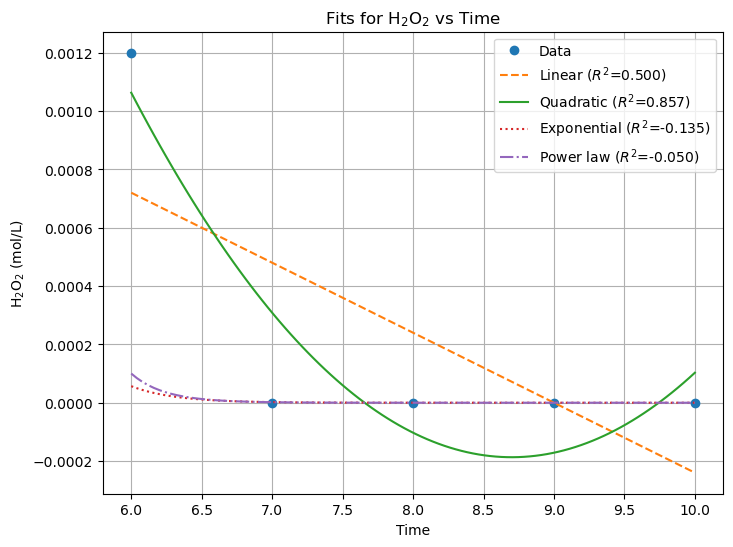

Linear fit:    y = -0.0002 * t + 0.0022      (R² = 0.500)
Quadratic fit: y = 0.0002 * t^2 + -0.0030 * t + 0.0128   (R² = 0.857)
Exponential fit: y = 19886.4543 * exp(-3.2791 * t)   (R² = -0.135)
Power law fit:   y = 1687611620904528773120.0000 * (t + 1)^-29.8510   (R² = -0.050)


In [62]:
# ...existing code...

# Time (min)
t = t[6:11]
# Propagation Rate (mm/min)
#data = solution[1, 6:16]  # H2O2cytosol

# # Array of your values in Python
# # Array of your values in Python
# t = t[0:11]
# # Array of your values in Python
data = [
0.0012,
1.50322E-07,
1.5829E-08,
1.12522E-09,
1.05082E-09,
]
#     1.49102e-12,
#     9.39337e-13,
#     6.87456e-13,
#     5.56539e-13,
#     4.79166e-13,
#     4.28974e-13,
#     3.95275e-13,
#     3.72328e-13,
#     3.56369e-13,
#     3.46075e-13,
#     3.38563e-13,
#     3.34602e-13,
#     3.32776e-13,
#     3.3272e-13,
#     3.34254e-13,
#     3.36914e-13,
#     3.40622e-13,
#     3.4513e-13,
#     3.50333e-13,
#     3.56132e-13,
#     3.62389e-13,
#     3.69104e-13,
#     3.76121e-13,
#     3.83515e-13,
#     3.91093e-13
# ]
# data = data[0:11]
# max_data = np.max(data)
# data = data / max_data


import matplotlib.pyplot as plt
import numpy as np

def r2(y, y_pred):
    ss_res = np.sum((y - y_pred) ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    return 1 - ss_res / ss_tot

# Linear fit
coeffs_lin = np.polyfit(t, data, 1)
data_lin = np.polyval(coeffs_lin, t)
r2_lin = r2(data, data_lin)

# Quadratic fit
coeffs_quad = np.polyfit(t, data, 2)
data_quad = np.polyval(coeffs_quad, t)
r2_quad = r2(data, data_quad)

# Exponential fit: y = a * exp(bx)
b_exp, loga_exp = np.polyfit(t, np.log(data), 1)
a_exp = np.exp(loga_exp)
data_exp = a_exp * np.exp(b_exp * t)
r2_exp = r2(data, data_exp)

# Power law fit: y = a * x^b (not meaningful if t=0, so skip or offset t if needed)
# If you want to fit a power law, use t+1 to avoid log(0)
logt = np.log(t + 1)
logd = np.log(data)
b_pow, loga_pow = np.polyfit(logt, logd, 1)
a_pow = np.exp(loga_pow)
data_pow = a_pow * (t + 1) ** b_pow
r2_pow = r2(data, data_pow)

# Plot all fits
t_fit = np.linspace(min(t), max(t), 100)
plt.figure(figsize=(8,6))
plt.plot(t, data, 'o', label='Data')
plt.plot(t_fit, np.polyval(coeffs_lin, t_fit), '--', label=f'Linear ($R^2$={r2_lin:.3f})')
plt.plot(t_fit, np.polyval(coeffs_quad, t_fit), '-', label=f'Quadratic ($R^2$={r2_quad:.3f})')
plt.plot(t_fit, a_exp * np.exp(b_exp * t_fit), ':', label=f'Exponential ($R^2$={r2_exp:.3f})')
plt.plot(t_fit, a_pow * (t_fit + 1) ** b_pow, '-.', label=f'Power law ($R^2$={r2_pow:.3f})')
plt.xlabel('Time')
plt.ylabel('H$_2$O$_2$ (mol/L)')
plt.title('Fits for H$_2$O$_2$ vs Time')
plt.legend()
plt.grid(True)
plt.show()
# ...existing code...

# ...existing code...

# Linear fit coefficients
m = coeffs_lin[0]
b_lin = coeffs_lin[1]

# Quadratic fit coefficients
a = coeffs_quad[0]
b_quad = coeffs_quad[1]
c = coeffs_quad[2]

# ...existing code...

# Linear fit: y = m * t + b
y_lin = f"{m:.4f} * t + {b_lin:.4f}     # R² = {r2_lin:.3f}"

# Quadratic fit: y = a * t^2 + b * t + c
y_quad = f"{a:.4f} * t^2 + {b_quad:.4f} * t + {c:.4f}   # R² = {r2_quad:.3f}"

# Exponential fit: y = a * exp(b * t)
y_exp = f"{a_exp:.4f} * exp({b_exp:.4f} * t)       # R² = {r2_exp:.3f}"

# Power law fit: y = a * (t + 1)^b
y_pow = f"{a_pow:.4f} * (t + 1)^{b_pow:.4f}        # R² = {r2_pow:.3f}"

print("Linear fit:    y = {:.4f} * t + {:.4f}      (R² = {:.3f})".format(m, b_lin, r2_lin))
print("Quadratic fit: y = {:.4f} * t^2 + {:.4f} * t + {:.4f}   (R² = {:.3f})".format(a, b_quad, c, r2_quad))
print("Exponential fit: y = {:.4f} * exp({:.4f} * t)   (R² = {:.3f})".format(a_exp, b_exp, r2_exp))
print("Power law fit:   y = {:.4f} * (t + 1)^{:.4f}   (R² = {:.3f})".format(a_pow, b_pow, r2_pow))
# ...existing code...

In [ ]:
# Define the parameterized model (copy your full ODEs here)
def model_noref(x, t, k, x0):

    def nox2_h2o2_rate(x, Vmax, K_act, n):
        """
        Returns NOX-driven H2O2 production in media (M/s), smoothly gated by cytosolic H2O2.
        x[1] is H2O2_cytosol. x0[1] is its baseline.
        """
        h = max(x[1] - x[28], 0.0)  # activate only above baseline

        # Hill activation
        f = (h**n) / (K_act**n + h**n) if h > 0 else 0.0
        f = (x[1]**n) / (K_act**n + x[1]**n) if x[1] > 0 else 0.0

        return Vmax * f
    
    def nox5_h2o2_rate(x, Vmax, K_act, n):
        """
        Returns NOX-driven H2O2 production in media (M/s), smoothly gated by cytosolic H2O2.
        x[1] is H2O2_cytosol. x0[1] is its baseline.
        """
        # Hill activation
        f = (x[29]**n) / (K_act**n + x[29]**n) if x[29] > 0 else 0.0

        return Vmax * f
    
    dxdt = np.zeros_like(x)
    # dxdt[0] = (k[0] * (x[1] - x[0]) * 10e-3 * 5.3e-6 * (1e9)) + k[31]
    nox2 = nox2_h2o2_rate(x, Vmax=k[32], K_act=1e-8, n=6)                     #nox2 
    nox5 = nox5_h2o2_rate(x, Vmax=k[33], K_act=2.8e-6, n=4)

    dxdt[0] = (k[0] * (x[1] - x[0]) * 10e-3 * 5.3e-6 * (1e9)) + nox2   # extracellular peroxide

    dxdt[1] = (((k[0] * x[0] * 10e-3 * 5.3e-6) / (1.15e-12))
               - ((k[0] * x[1] * 10e-3 * 5.3e-6) / (1.15e-12))
               - 2 * (k[22] * x[1] * 10e-3 * 2.98e-9) / (1.53e-14)              # peroxisomal H2O2     
               - k[2] * x[2] * x[1]                             # GPx reduction of H2O2
               - k[5] * x[7] * x[1]                                   # catalase reaction
               - k[7] * x[9] * x[1]                                   # peroxiredoxin oxidation
               - k[8] * x[10] * x[1]                                  # overoxidized peroxiredoxin
               - k[13] * x[15] * x[1]                                 # Protein monothiol oxidation
               - k[17] * x[20] * x[1]                                 # Protein dithiol oxidation
               + k[1]                                                          # intracellular peroxide production
               + k[29] * x[25] * x[27]                                      # superoxide dismutase reduction and oxidation by superoxide
               + nox5)                                                        # nox5 h2o2 production

    dxdt[2] = (- k[2] * x[2] * x[1]
               + k[4] * x[4] * x[5])
    
    dxdt[3] = k[2] * x[2] * x[1] - k[3] * x[3] * x[5]
    dxdt[4] = k[3] * x[3] * x[5] - k[4] * x[4] * x[5]
    dxdt[5] = (- k[3] * x[3] * x[5]
               - k[4] * x[4] * x[5]
               - 2 * k[12] * x[5]
               - k[14] * x[16] * x[5]
               - k[16] * x[16] * x[5]
               + 2 * k[19] * x[6] * x[22]
               + k[23] 
               - k[25])
    dxdt[6] = (k[4] * x[4] * x[5] + k[12] * x[5] +
               k[16] * x[19] * x[5] - k[19] * x[6] * x[22] 
               - k[24] * x[6] / x0[6]
               - k[25] * x[6] / x0[6]
               )
    dxdt[7] = 0
    dxdt[8] = (k[22] * x[1] * 10e-3 * 2.98e-9) / (1.53e-14) - k[5] * x[7] * x[8]
    dxdt[9] = - k[7] * x[9] * x[1] + k[11] * x[12] * x[13]
    dxdt[10] = (k[7] * x[9] * x[1] - k[8] * x[10] * x[1] +
                k[9] * x[11] - k[10] * x[10])
    dxdt[11] = k[8] * x[10] * x[1] - k[9] * x[11]
    dxdt[12] = k[10] * x[10] - k[11] * x[12] * x[13]
    dxdt[13] = (- k[11] * x[12] * x[13] 
                - k[18] * x[21] * x[13] 
                + k[20] * x[14] * x[22] 
                - k[26] 
                + k[27])
    dxdt[14] = (k[11] * x[12] * x[13] + k[18] * x[21] * x[13] -
                k[20] * x[14] * x[22])

    dxdt[15] = (- k[13] * x[15] * (x[1])
                + k[15] * x[18] * (x[17]))

    dxdt[16] = k[13] * x[15] * x[1] - k[14] * x[16] * x[5]
    dxdt[17] = k[14] * x[16] * x[5] - k[15] * x[18] * x[17]
    dxdt[18] = k[16] * x[19] * x[5] - k[15] * x[18] * x[17]
    
    dxdt[19] = (k[15] * x[18] * x[17] 
                - k[16] * x[19] * x[5])
    
    dxdt[20] = - k[17] * x[20] * x[1] + k[18] * x[21] * x[13]
    dxdt[21] = k[17] * x[20] * x[1] - k[18] * x[21] * x[13]

    #NADPH
    dxdt[22] = (- k[19] * x[6] * x[22] 
                - k[20] * x[14] * x[22] 
                #- k[28] * x[22]                                         # nox generation of superoxide
                + k[21] * x[23] / (k[6] + x[23]))
    #NADP+
    dxdt[23] = (k[19] * x[6] * x[22] 
                + k[20] * x[14] * x[22] 
                #+ k[28] * x[22]                                         # nox generation of superoxide and nadp+
                - k[21] * x[23] / (k[6] + x[23]))

    dxdt[24] = (k[0] * (x[25] - x[24]) * 10e-3 * 1.02e-5 * (1e9)               # superoxide media
                + k[28] * x[22])
    
    dxdt[25] = (((k[0] * x[24] * 10e-3 * 1.02e-5) / (9.16e-13))                 # superoxide cytosol
               - ((k[0] * x[25] * 10e-3 * 1.02e-5) / (9.16e-13))
               - k[29] * x[25] * x[26]
               - k[29] * x[25] * x[27]
               + k[30])
    
    dxdt[26] = (k[29] * x[25] * x[27] 
                - k[29] * x[25] * x[26])

    dxdt[27] = (k[29] * x[25] * x[26] 
                - k[29] * x[25] * x[27])
    
    #dxdt[28] = 0#(((k[0] * x[29] * 10e-3 * 1.02e-5) / (9.16e-13))               # calcium cytosol
               #- ((k[0] * x[28] * 10e-3 * 1.02e-5) / (9.16e-13)))
               #+ (200e-6*(x[28]**2/(0.6e-6**2+x[28]**2))))
    
    #dxdt[29] = ((k[0] * 1e-3 * (x[28] - x[29]) * 10e-3 * 1.02e-5 * (1e9)) + k[32])               # calcium media
    
    return dxdt
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


t = np.linspace(0, 200, 201)

xnew = x0.copy()
k = k.copy()
k[0] = 2e-2
k[1] = 1.1e-7#24e-7 #ss at 23.75e-7
x0[1] = 1.0e-9
k[31] = 0
k[32] = 0
t1 = t[np.where(t <= 5)]
t2 = t[np.where(t > 5)]
solution1 = solve_ivp(lambda t, y: model_noref(y, t1, k, x0), (0, t1[-1]), xnew, t_eval=t1, method='Radau', atol=1e-10, rtol=1e-8).y
xnew1 = solution1[:, -1]
xnew1[1] = solution1[1, -1] + 0.0012  # Add 1 µM H2O2 to cytosol at t=5s
solution2 = solve_ivp(lambda t, y: model_noref(y, t2, k, xnew1), (t1[-1], t2[-1]), xnew1, t_eval=t2, method='Radau', atol=1e-10, rtol=1e-8).y
solution = np.hstack((solution1, solution2))

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(t[0:30], solution[1, 0:30], label='H2O2cytosol')
plt.xlabel('Time')
plt.ylabel('Concentration')
plt.title(f'H2O2cytosol Dynamics, H2O2 Cytosol = {x0[1]}M')
plt.yscale('log')
print(solution[1, -1])

plt.subplot(1, 2, 2)
plt.plot(t[0:30], solution[0, 0:30], label='H2O2media')
plt.xlabel('Time [s]')
plt.ylabel('Concentration [M]')
plt.title(f'H2O2media Dynamics, H2O2 Media = {x0[0]}M')
plt.yscale('log')
plt.legend()

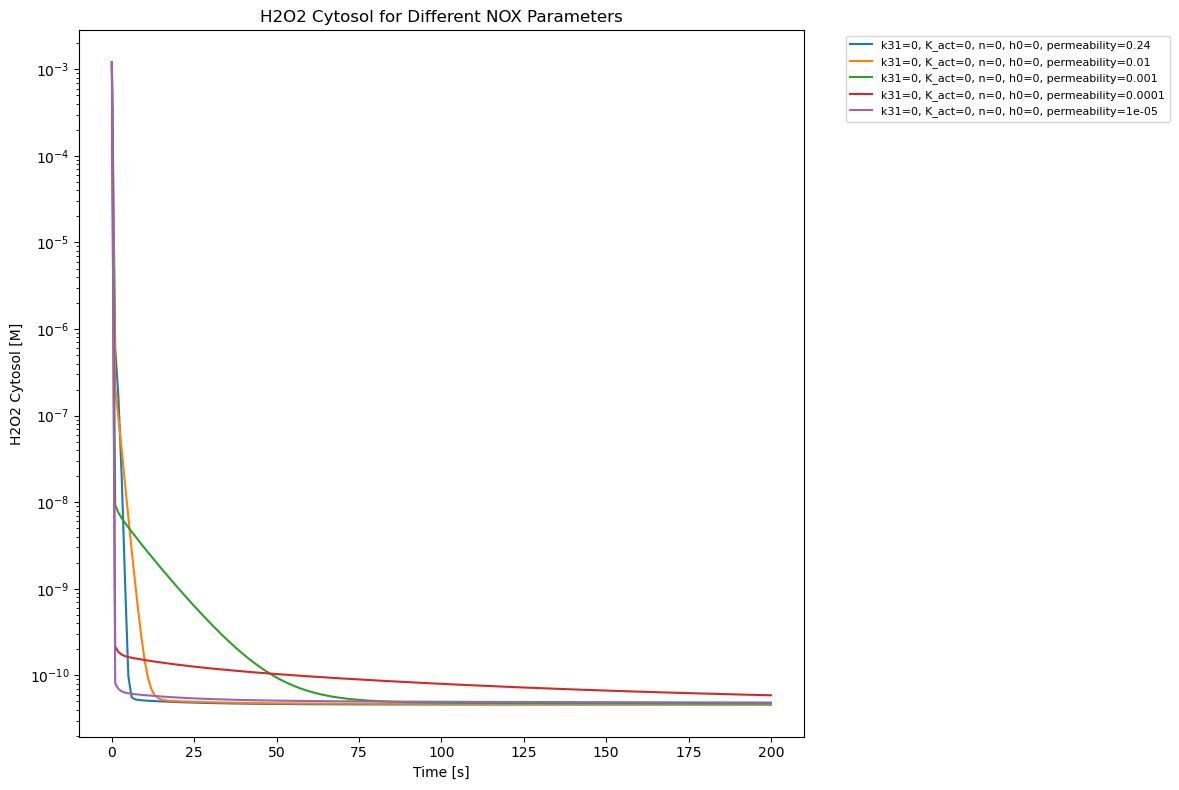

In [63]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Parameter lists
k31_list = [0]#[8.87e-8]
K_act_list = [0]#[1e-9, 1e-8]
n_list = [0]#[1,3]
h_baseline_list = [0]#[4.5e-11, 1e-9]
permeability_coefficient_list = [24e-2, 1e-2, 1e-3, 1e-4, 1e-5]

# Store results for plotting
results = []
# Initial conditions

xnew = x0.copy()

xnew[1] = 0.0012  # Set initial H2O2cytosol concentration

# Define the parameterized model (copy your full ODEs here)
def model_noref_param(x, t, k, xnew, k31, K_act, n, h_baseline, permeability_coefficient_list):
    k = k.copy()
    k[31] = k31
    def nox_h2o2_rate(x, Vmax, K_act, n, h_baseline):
        h = max(x[1] - h_baseline, 0.0)
        f = (h**n) / (K_act**n + h**n) if h > 0 else 0.0
        return Vmax * f
    dxdt = np.zeros_like(x)
    k31_hill = nox_h2o2_rate(x, Vmax=k[31], K_act=K_act, n=n, h_baseline=h_baseline)
    k[0] = permeability_coefficient_list

    dxdt[0] = (k[0] * (x[1] - x[0]) * 10e-3 * 1.02e-5 * (1e9)) + k31_hill
    # --- Copy the rest of your ODEs from model_noref here ---

    dxdt[1] = (((k[0] * x[0] * 10e-3 * 5.3e-6) / (1.15e-12))
               - ((k[0] * x[1] * 10e-3 * 5.3e-6) / (1.15e-12))
               #- 2 * (k[22] * x[1] * 10e-3 * 2.98e-9) / (1.53e-14)              # peroxisomal H2O2     
               - k[2] * x[2] * x[1]                             # GPx reduction of H2O2
               - k[5] * x[7] * x[1]                                   # catalase reaction
               - k[7] * x[9] * x[1]                                   # peroxiredoxin oxidation
               - k[8] * x[10] * x[1]                                  # overoxidized peroxiredoxin
               - k[13] * x[15] * x[1]                                 # Protein monothiol oxidation
               - k[17] * x[20] * x[1]                                 # Protein dithiol oxidation
               + k[1]                                                          # intracellular peroxide production
               + k[29] * x[25] * x[27])                                      # superoxide dismutase reduction and oxidation by superoxide

    dxdt[2] = (- k[2] * x[2] * x[1]
               + k[4] * x[4] * x[5])
    
    dxdt[3] = k[2] * x[2] * x[1] - k[3] * x[3] * x[5]
    dxdt[4] = k[3] * x[3] * x[5] - k[4] * x[4] * x[5]
    dxdt[5] = (- k[3] * x[3] * x[5]
               - k[4] * x[4] * x[5]
               - 2 * k[12] * x[5]
               - k[14] * x[16] * x[5]
               - k[16] * x[16] * x[5]
               + 2 * k[19] * x[6] * x[22]
               + k[23] 
               - k[25])
    dxdt[6] = (k[4] * x[4] * x[5] + k[12] * x[5] +
               k[16] * x[19] * x[5] - k[19] * x[6] * x[22] 
               - k[24] * x[6] / x0[6]
               - k[25] * x[6] / x0[6]
               )
    dxdt[7] = 0
    dxdt[8] = (k[22] * x[1] * 10e-3 * 2.98e-9) / (1.53e-14) - k[5] * x[7] * x[8]
    dxdt[9] = - k[7] * x[9] * x[1] + k[11] * x[12] * x[13]
    dxdt[10] = (k[7] * x[9] * x[1] - k[8] * x[10] * x[1] +
                k[9] * x[11] - k[10] * x[10])
    dxdt[11] = k[8] * x[10] * x[1] - k[9] * x[11]
    dxdt[12] = k[10] * x[10] - k[11] * x[12] * x[13]
    dxdt[13] = (- k[11] * x[12] * x[13] 
                - k[18] * x[21] * x[13] 
                + k[20] * x[14] * x[22] 
                - k[26] 
                + k[27])
    dxdt[14] = (k[11] * x[12] * x[13] + k[18] * x[21] * x[13] -
                k[20] * x[14] * x[22])

    dxdt[15] = (- k[13] * x[15] * (x[1])
                + k[15] * x[18] * (x[17]))

    dxdt[16] = k[13] * x[15] * x[1] - k[14] * x[16] * x[5]
    dxdt[17] = k[14] * x[16] * x[5] - k[15] * x[18] * x[17]
    dxdt[18] = k[16] * x[19] * x[5] - k[15] * x[18] * x[17]
    
    dxdt[19] = (k[15] * x[18] * x[17] 
                - k[16] * x[19] * x[5])
    
    dxdt[20] = - k[17] * x[20] * x[1] + k[18] * x[21] * x[13]
    dxdt[21] = k[17] * x[20] * x[1] - k[18] * x[21] * x[13]

    #NADPH
    dxdt[22] = (- k[19] * x[6] * x[22] 
                - k[20] * x[14] * x[22] 
                #- k[28] * x[22]                                         # nox generation of superoxide
                + k[21] * x[23] / (k[6] + x[23]))
    #NADP+
    dxdt[23] = (k[19] * x[6] * x[22] 
                + k[20] * x[14] * x[22] 
                #+ k[28] * x[22]                                         # nox generation of superoxide and nadp+
                - k[21] * x[23] / (k[6] + x[23]))

    dxdt[24] = (k[0] * (x[25] - x[24]) * 10e-3 * 1.02e-5 * (1e9)               # superoxide media
                + k[28] * x[22])
    
    dxdt[25] = (((k[0] * x[24] * 10e-3 * 1.02e-5) / (9.16e-13))                 # superoxide cytosol
               - ((k[0] * x[25] * 10e-3 * 1.02e-5) / (9.16e-13))
               - k[29] * x[25] * x[26]
               - k[29] * x[25] * x[27]
               + k[30])
    
    dxdt[26] = (k[29] * x[25] * x[27] 
                - k[29] * x[25] * x[26])

    dxdt[27] = (k[29] * x[25] * x[26] 
                - k[29] * x[25] * x[27])
    
    #dxdt[28] = 0#(((k[0] * x[29] * 10e-3 * 1.02e-5) / (9.16e-13))               # calcium cytosol
               #- ((k[0] * x[28] * 10e-3 * 1.02e-5) / (9.16e-13)))
               #+ (200e-6*(x[28]**2/(0.6e-6**2+x[28]**2))))
    
    #dxdt[29] = ((k[0] * 1e-3 * (x[28] - x[29]) * 10e-3 * 1.02e-5 * (1e9)) + k[32])               # calcium media
    
    return dxdt


# Time vector
t = np.linspace(0, 200, 201)

# Iterate and solve
for permeability_coefficient in permeability_coefficient_list:
    for k31 in k31_list:
        for K_act in K_act_list:
            for n_val in n_list:
                for h_baseline in h_baseline_list:
                    k_test = k.copy()
                    x0_test = xnew.copy()
                    # ODE function for solve_ivp (note: t and y order for solve_ivp)
                    ode_func = lambda t, y: model_noref_param(y, t, k_test, x0_test, k31, K_act, n_val, h_baseline, permeability_coefficient)
                    sol = solve_ivp(ode_func, (0, 200), x0_test, t_eval=t, method='Radau', atol=1e-10, rtol=1e-8)
                    results.append({
                        'k31': k31,
                        'K_act': K_act,
                        'n': n_val,
                        'h_baseline': h_baseline,
                        't': sol.t,
                        'H2O2_cytosol': sol.y[1],
                        'permeability_coefficient': permeability_coefficient
                    })
               
# Plotting
plt.figure(figsize=(12, 8))
for res in results:
    label = f"k31={res['k31']}, K_act={res['K_act']}, n={res['n']}, h0={res['h_baseline']}, permeability={res['permeability_coefficient']}"
    plt.plot(res['t'], res['H2O2_cytosol'], label=label)
plt.xlabel('Time [s]')
plt.ylabel('H2O2 Cytosol [M]')
plt.title('H2O2 Cytosol for Different NOX Parameters')
plt.yscale('log')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

for changing scavenger activation

Completed simulation with k[0] = 0
Completed simulation with k[22] = 0
Completed simulation with k[2] = 0
Completed simulation with k[5] = 0
Completed simulation with k[7] = 0
Completed simulation with k[8] = 0
Completed simulation with k[9] = 0
Completed simulation with k[13] = 0
Completed simulation with k[17] = 0
Completed simulation with ALL major antioxidants = 0


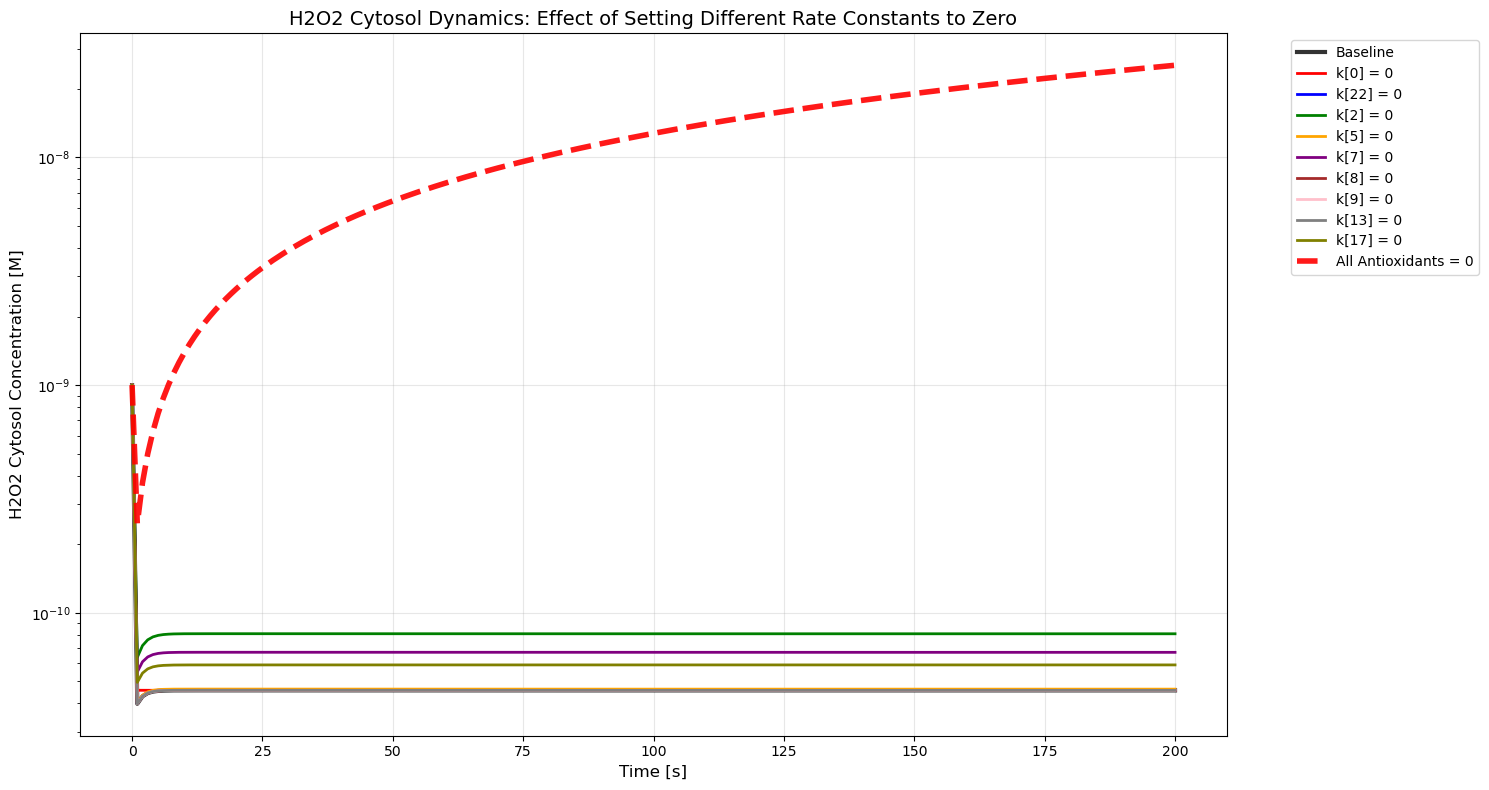


Final H2O2 cytosol concentrations at t=200s:
------------------------------------------------------------
Baseline                 : 4.56e-11 M
k[0] = 0                 : 4.56e-11 M
k[22] = 0                : 4.58e-11 M
k[2] = 0                 : 8.09e-11 M
k[5] = 0                 : 4.62e-11 M
k[7] = 0                 : 6.70e-11 M
k[8] = 0                 : 4.56e-11 M
k[9] = 0                 : 4.56e-11 M
k[13] = 0                : 4.56e-11 M
k[17] = 0                : 5.90e-11 M
All Antioxidants = 0     : 2.54e-08 M


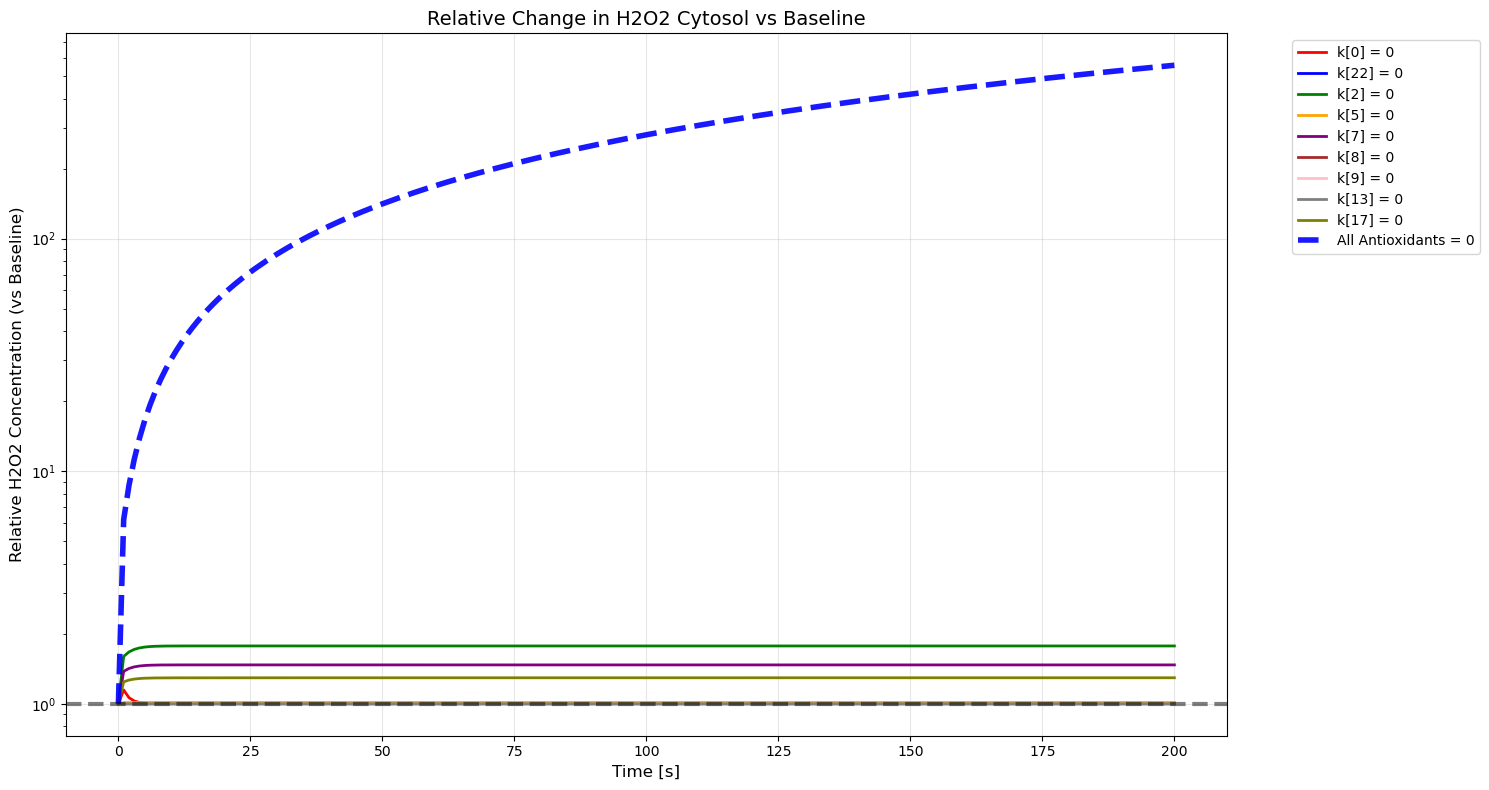

In [64]:
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import numpy as np

# Parameters to test (setting each to zero one at a time)
params_to_test = {
    'k[0]': 0,   # Plasma membrane permeability
    'k[22]': 22, # Peroxisomal membrane permeability  
    'k[2]': 2,   # GPx clearance
    'k[5]': 5,   # Catalase clearance
    'k[7]': 7,   # Prx clearance
    'k[8]': 8,   # Prx over-oxidation
    'k[9]': 9,   # Prx reduction
    'k[13]': 13, # Protein monothiol oxidation
    'k[17]': 17  # Protein dithiol oxidation
}

# Store original values
k_original = k.copy()

# Set up time vector
t = np.linspace(0, 200, 201)

# Store results for comparison
results = {}

# Run baseline case first
solution_baseline = solve_ivp(
    lambda t, y: model_noref(y, t, k_original, x0),
    (0, 200),
    x0,
    method='Radau',
    t_eval=t,
    atol=1e-10,
    rtol=1e-8
)
results['Baseline'] = solution_baseline.y[1]

# Test each parameter individually
for param_name, param_index in params_to_test.items():
    # Reset to original values
    k_test = k_original.copy()
    
    # Set specific parameter to zero
    k_test[param_index] = 0
    
    # Run simulation
    solution = solve_ivp(
        lambda t, y: model_noref(y, t, k_test, x0),
        (0, 200),
        x0,
        method='Radau',
        t_eval=t,
        atol=1e-10,
        rtol=1e-8
    )
    
    # Store results
    results[f'{param_name} = 0'] = solution.y[1]
    
    print(f"Completed simulation with {param_name} = 0")

# NEW: Test with ALL major antioxidants set to zero
k_all_zero = k_original.copy()
major_antioxidants = [2, 5, 7, 8, 13, 17, 22]  # GPx, Catalase, Prx, Prx-over, Protein oxidations

for param_index in major_antioxidants:
    k_all_zero[param_index] = 0

solution_all_zero = solve_ivp(
    lambda t, y: model_noref(y, t, k_all_zero, x0),
    (0, 200),
    x0,
    method='Radau',
    t_eval=t,
    atol=1e-10,
    rtol=1e-8
)
results['All Antioxidants = 0'] = solution_all_zero.y[1]
print("Completed simulation with ALL major antioxidants = 0")

# Plot all results
plt.figure(figsize=(15, 8))

# Plot baseline
plt.plot(t, results['Baseline'], 'k-', linewidth=3, label='Baseline', alpha=0.8)

# Plot each parameter test
colors = ['red', 'blue', 'green', 'orange', 'purple', 'brown', 'pink', 'gray', 'olive']
for i, (param_name, _) in enumerate(params_to_test.items()):
    label = f'{param_name} = 0'
    plt.plot(t, results[label], color=colors[i], linewidth=2, label=label)

# Plot the "all zero" case with a special style
plt.plot(t, results['All Antioxidants = 0'], 'r--', linewidth=4, 
         label='All Antioxidants = 0', alpha=0.9)

plt.xlabel('Time [s]', fontsize=12)
plt.ylabel('H2O2 Cytosol Concentration [M]', fontsize=12)
plt.title('H2O2 Cytosol Dynamics: Effect of Setting Different Rate Constants to Zero', fontsize=14)
plt.yscale('log')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Print final concentrations for comparison
print("\nFinal H2O2 cytosol concentrations at t=200s:")
print("-" * 60)
for case_name, concentrations in results.items():
    print(f"{case_name:25}: {concentrations[-1]:.2e} M")

# Create a second plot showing relative changes
plt.figure(figsize=(15, 8))

baseline_final = results['Baseline'][-1]
for i, (param_name, _) in enumerate(params_to_test.items()):
    label = f'{param_name} = 0'
    relative_change = results[label] / results['Baseline']
    plt.plot(t, relative_change, color=colors[i], linewidth=2, label=label)

# Add the "all zero" case to relative plot
relative_all_zero = results['All Antioxidants = 0'] / results['Baseline']
plt.plot(t, relative_all_zero, 'b--', linewidth=4, 
         label='All Antioxidants = 0', alpha=0.9)

plt.xlabel('Time [s]', fontsize=12)
plt.ylabel('Relative H2O2 Concentration (vs Baseline)', fontsize=12)
plt.title('Relative Change in H2O2 Cytosol vs Baseline', fontsize=14)
plt.yscale('log')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.axhline(y=1, color='black', linewidth = 3, linestyle='--', alpha=0.5, label='Baseline')
plt.tight_layout()
plt.show()

Andy Model

In [65]:
import numpy as np
from scipy.integrate import odeint

def blap_ODE_system(endtime, step, celldens, protein_abund, blap_conc, parameter_pctchange=None, species_pctchange=None):
    """
    Model for compartmentalized hydrogen peroxide consumption
    
    Parameters:
    -----------
    endtime : float
        End time for simulation
    step : float
        Maximum step size for solver
    celldens : float
        Cell density
    protein_abund : array-like
        Protein abundance values
    blap_conc : float
        B-lap concentration
    parameter_pctchange : array-like, optional
        Percentage changes for parameters
    species_pctchange : array-like, optional
        Percentage changes for species
    
    Returns:
    --------
    time_series : ndarray
        Array containing time points and state variables
    """
    
    # Establish genes of interest and index
    genes = ["GPX1", "GPX2", "GPX3", "GPX4", "GPX5", "GPX6", "GPX7", "GPX8", "PRDX1", "PRDX2",
             "PRDX2", "PRDX3", "PRDX6", "CAT", "TXN", "TXN2", "TXNRD1", "TXNRD2", "TXNRD3", "GLRX", 
             "GLRX2", "G6PD", "GLUD1", "GSR", "GSTP1", "POR", "NQO1", "SOD1", "SOD2", "SOD3", 
             "AQP3", "AQP8", "AQP9", "GCLC"]

    # Solver Parameters
    ti = 0  # start time
    tf = endtime  # stop time
    tspan = (ti, tf)
    
    # Define parameter values
    k = np.zeros(36)
    
    # Rxns (Cytosolic)
    
    # H2O2 Transport
    # Permeability constant (plasma membrane)
    # H2O2cyt -> H2O2out
    k[0] = 2e-4 * protein_abund[29] / 0.0302  # cm/s
    
    # Mitochondrial production of H2O2in
    k[1] = 4
    
    # GPx1_red reacting with H2O2in
    # H2O2cyt + GPX1r -> GPX1o ; EC 1.11.1.9
    # Updated 9/22 with Kassi Stein PLoS Comp Bio paper k2
    k[2] = 60  # uM-1*s-1 (60 uM-1*s-1 Kassi paper)
    
    # GPx1_ox reacting with GSH
    # GPX1o + GSH -> GPX1-SG
    # Updated 9/22 with KS PLoS Comp Bio paper k3
    k[3] = 0.04  # uM-1*s-1
    
    # GPx1-SG reacting with GSH
    # GPX1-SG + GSH -> GPX1r + GSSG
    # Updated 9/22 with KS PLoS Comp Bio Paper k4
    k[4] = 10  # uM-1*s-1
    
    # Catalase reacts with H2O2 inside peroxisome
    # H2O2p ->
    # Updated 10/6
    k[5] = 34  # uM-1*s-1
    
    # Km of NADP+
    # Updated 9/22 with KS PLoS Comp Bio Paper k4
    k[6] = 57  # uM
    
    # Peroxiredoxin is oxidized by H2O2
    # Updated 10/6
    k[7] = 40  # uM-1*s-1
    
    # Oxidized peroxiredoxin is over-oxidized by H2O2
    # Updated 10/6
    k[8] = 0.072  # uM-1*s-1
    
    # Reduction of overoxidized Prx by Srx enzyme
    k[9] = 3e-3  # s-1
    
    # Self-catalyzed disulfide formation of Prx-SS from Prx-SOH
    k[10] = 15  # s-1
    
    # Peroxiredoxin is reduced by Thioredoxin
    # Updated 10/6
    k[11] = 2.1  # uM-1*s-1
    
    # Auto-oxidation of GSH
    k[12] = 7.4e-05  # s-1
    
    # Protein monothiol oxidized by H2O2
    # Updated 10/6
    k[13] = 0.01  # uM-1*s-1
    
    # Oxidized Protein monothiol glutathionylated by GSH
    # Updated 10/6
    k[14] = 0.12  # uM-1*s-1
    
    # Grx-SH de-glutathionylates Protein-SSG
    # Updated 10/6
    k[15] = 0.091  # uM-1*s-1
    
    # GSH de-glutathionylates Grx-SSG
    # Updated 10/6
    k[16] = 0.037  # uM-1*s-1
    
    # Protein dithiol oxidized by H2O2
    # Updated 10/6
    k[17] = 5e-1  # uM-1*s-1
    
    # Protein disulfide reduced by Trx1
    # Updated 10/6
    k[18] = 1e-1  # uM-1*s-1
    
    # GSSG reduced by GR
    k[19] = 3.2 * protein_abund[22] / 0.1419  # uM-1*s-1
    
    # Oxidized Thioredoxin reduced by TrxR
    k[20] = 2e1 * protein_abund[15] / 0.1816  # uM-1*s-1
    
    # Production of NADPH by G6P-DH
    k[21] = 3.75e2 * (protein_abund[20] + protein_abund[21]) / (0.2581 + 0.5159)  # uM/s
    
    # Permeability constant (peroxisomal membrane)
    k[22] = 3e-3  # cm/s
    
    # GSH synthesis
    k[23] = 4.1e-1 * protein_abund[32] / .0075  # uM/s 4.1e-7
    
    # GSSG efflux
    k[24] = 1.2e-2  # uM/s 1.2e-8
    
    # GSH + GSSG efflux
    k[25] = 1.2e-1  # uM/s 1.2e-7
    
    # NQO1 Reaction; b-lap Q->HQ
    k[28] = 161.5 * protein_abund[25] / .2905  # 1/uM-s
    
    # b-lap HQ->SQ
    k[29] = 3e2  # 1/uM-s
    
    # b-lap SQ->Q
    k[30] = 3e2  # 1/uM-s
    
    # SOD
    k[31] = 6400.0 * protein_abund[26] / 1.6641  # 1/uM-s
    
    # CPR
    k[32] = 1900 * protein_abund[24] / 0.2231  # 1/uM-s
    
    # blap perm
    k[33] = 1e-6  # cm/s
    
    # blapHQ + GSH -> blapHQ-SG
    k[34] = 0.05 * protein_abund[23] / 2.6052  # 1/uM-s
    
    # blapHQ-SG -> blapHQ-SG extracell
    k[35] = 1e-6  # cm/s
    
    if parameter_pctchange is not None:
        k = k * parameter_pctchange
    
    # Defining initial Conditions (Concentrations in uM = micromoles/Liter)
    # Defining the array, x0, that will house initial concentrations
    x0 = np.zeros(32)
    
    # H2O2media
    x0[0] = 0.0
    
    # H2O2cytosol
    x0[1] = 1.0e-3
    
    # GPXr
    x0[2] = protein_abund[0]
    
    # GPXo
    x0[3] = x0[2] / 5e9
    
    # GPX-SG
    x0[4] = x0[2] / 5e9
    
    # GSH
    x0[5] = 368
    
    # GSSG
    x0[6] = x0[5] / 206
    
    # Catalase
    x0[7] = protein_abund[12]
    
    # H2O2peroxisome
    x0[8] = 1.0e-10
    
    # Prx1/2-SH
    x0[9] = protein_abund[8] + protein_abund[9]
    
    # Prx1/2-SOH
    x0[10] = x0[9] / 1.92e9
    
    # Prx1/2-SOOH
    x0[11] = x0[9] / 1.92e9
    
    # Prx1/2-SS
    x0[12] = x0[9] * (.5 / 100)
    
    # Trx1-SH
    x0[13] = protein_abund[13]
    
    # Trx1-SS
    x0[14] = x0[13] / 5.7
    
    # Pr-SH
    x0[15] = 50  # 1.22e2
    
    # Pr-SOH
    x0[16] = x0[15] * (.5 / 100)
    
    # Pr-SSG
    x0[17] = x0[15] * (.5 / 100)
    
    # Grx-SH
    x0[18] = protein_abund[18]
    
    # Grx-SSG
    x0[19] = x0[18] * (.5 / 100)
    
    # Pr-(SH)2
    x0[20] = 450
    
    # Pr-SS
    x0[21] = x0[20] * (.5 / 100)
    
    # NADPH
    x0[22] = 3.0e1
    
    # NADP+
    x0[23] = x0[22] / 100
    
    # blap Q
    x0[24] = 0
    
    # blap HQ
    x0[25] = 0
    
    # blap SQ
    x0[26] = 0
    
    # superO2
    x0[27] = 0
    
    # oxygen
    x0[28] = 2.6e2
    
    # blap extracell
    x0[29] = blap_conc
    
    # blap-GSH
    x0[30] = 0
    
    # blap-GSH extracell
    x0[31] = 0
    
    if species_pctchange is not None:
        x0 = x0 * species_pctchange
        
    x0[3] = x0[2] / 5e9  # GPXo
    x0[4] = x0[2] / 5e9  # GPX-SG
    x0[6] = x0[5] / 206  # GSSG
    x0[10] = x0[9] / 1.92e9  # Prx-SOH
    x0[11] = x0[9] / 1.92e9  # Prx-SOOH
    x0[12] = x0[9] * (.5 / 100)  # Prx-SS
    x0[14] = x0[13] / 5.7  # Trx1-SS
    x0[16] = x0[15] * (.5 / 100)  # Pr-SOH
    x0[17] = x0[15] * (.5 / 100)  # Pr-SSG
    x0[19] = x0[18] * (.5 / 100)  # Grx-SSG
    x0[21] = x0[20] * (.5 / 100)  # Pr-SS
    x0[23] = x0[22] / 100  # NADP+
    
    def ode_sys(t, x, k, celldens):
        # Apply bounds to state variables to prevent them from going too high/low
        dxdt = np.zeros_like(x)
        
        x_area = celldens * 1 * 1000 * 4 * np.pi * .00001**2  # in cm^2
        c_area = celldens * 1 * 4 * np.pi * .001**2 - x_area  # in cm^2
        x_vol = celldens * 1 * 1000 * 4/3 * np.pi * .00001**3  # in cm^3
        c_vol = celldens * 1 * 4/3 * np.pi * .001**3 - x_vol  # in cm^3
        m_vol = 1000 - x_vol - c_vol  # in cm^3
        
        # Cytosolic Dynamics
        dxdt[0] = k[0] * c_area * (x[1] - x[0]) / m_vol  # H2O2 extracellular
        
        dxdt[1] = (k[0] * c_area * (x[0] - x[1]) / c_vol - 
                  k[22] * x_area * (x[1] - x[8]) / c_vol + 
                  k[1] - k[2] * x[2] * (x[1] - x0[1]) - 
                  k[7] * x[9] * (x[1] - x0[1]) - k[8] * x[10] * (x[1] - x0[1]) - 
                  k[13] * x[15] * (x[1] - x0[1]) - k[17] * x[20] * (x[1] - x0[1]) + 
                  k[31] * x[27]**2)  # H2O2 cytosol
        
        dxdt[2] = -k[2] * x[2] * (x[1] - x0[1]) + k[4] * (x[4] - x0[4]) * x[5]  # GPXr
        
        dxdt[3] = k[2] * x[2] * (x[1] - x0[1]) - k[3] * (x[3] - x0[3]) * x[5]  # GPXo
        
        dxdt[4] = k[3] * (x[3] - x0[3]) * x[5] - k[4] * (x[4] - x0[4]) * x[5]  # GPX-SG
        
        dxdt[5] = (-k[3] * (x[3] - x0[3]) * x[5] - 
                  k[4] * (x[4] - x0[4]) * x[5] - 
                  2 * k[12] * x[5] - k[14] * (x[16] - x0[16]) * x[5] - 
                  k[34] * x[25] * x[5] - k[16] * (x[19] - x0[19]) * x[5] + 
                  2 * k[19] * (x[6] - x0[6]) * x[22] + 
                  k[23] - k[25] * x[5] * x[6])  # GSH
        
        dxdt[6] = (k[4] * (x[4] - x0[4]) * x[5] + k[12] * x[5] + 
                  k[16] * (x[19] - x0[19]) * x[5] - 
                  k[19] * (x[6] - x0[6]) * x[22] - 
                  k[24] - k[25] * x[5] * x[6])  # GSSG
        
        dxdt[7] = 0  # FeCat
        
        dxdt[8] = k[22] * x_area * (x[1] - x[8]) / x_vol - k[5] * x[7] * (x[8] - x0[8])  # H2O2 peroxisome
        
        dxdt[9] = -k[7] * x[9] * (x[1] - x0[1]) + k[11] * (x[12] - x0[12]) * x[13]  # Prx-SH
        
        dxdt[10] = (k[7] * x[9] * (x[1] - x0[1]) - k[8] * x[10] * (x[1] - x0[1]) + 
                   k[9] * (x[11] - x0[11]) - k[10] * x[10])  # Prx-SOH
        
        dxdt[11] = k[8] * x[10] * (x[1] - x0[1]) - k[9] * (x[11] - x0[11])  # Prx-SOOH
        
        dxdt[12] = k[10] * x[10] - k[11] * (x[12] - x0[12]) * x[13]  # Prx-SS
        
        dxdt[13] = (-k[11] * (x[12] - x0[12]) * x[13] - 
                   k[18] * (x[21] - x0[21]) * x[13] + 
                   k[20] * (x[14] - x0[14]) * x[22])  # Trx-SH
        
        dxdt[14] = (k[11] * (x[12] - x0[12]) * x[13] + 
                   k[18] * (x[21] - x0[21]) * x[13] - 
                   k[20] * (x[14] - x0[14]) * x[22])  # Trx-SS
        
        dxdt[15] = -k[13] * x[15] * (x[1] - x0[1]) + k[15] * x[18] * (x[17] - x0[17])  # Pr-SH
        
        dxdt[16] = k[13] * x[15] * (x[1] - x0[1]) - k[14] * (x[16] - x0[16]) * x[5]  # Pr-SOH
        
        dxdt[17] = k[14] * (x[16] - x0[16]) * x[5] - k[15] * x[18] * (x[17] - x0[17])  # Pr-SSG
        
        dxdt[18] = k[16] * (x[19] - x0[19]) * x[5] - k[15] * x[18] * (x[17] - x0[17])  # Grx-SH
        
        dxdt[19] = k[15] * x[18] * (x[17] - x0[17]) - k[16] * (x[19] - x0[19]) * x[5]  # Grx-SSG
        
        dxdt[20] = -k[17] * x[20] * (x[1] - x0[1]) + k[18] * (x[21] - x0[21]) * x[13]  # Pr-(SH)2
        
        dxdt[21] = k[17] * x[20] * (x[1] - x0[1]) - k[18] * (x[21] - x0[21]) * x[13]  # Pr-SS
        
        dxdt[22] = (-k[19] * (x[6] - x0[6]) * x[22] - 
                   k[20] * (x[14] - x0[14]) * x[22] - 
                   k[28] * x[24] * x[22] + 
                   k[21] * (x[23] - x0[23]) / (k[6] + x[23]))  # NADPH
        
        dxdt[23] = (k[19] * (x[6] - x0[6]) * x[22] + 
                   k[20] * (x[14] - x0[14]) * x[22] + 
                   k[28] * x[24] * x[22] - 
                   k[21] * (x[23] - x0[23]) / (k[6] + x[23]))  # NADP+
        
        dxdt[24] = (k[33] * c_area * (x[29] - x[24]) / c_vol + 
                   k[30] * x[26] * x[28] - k[28] * x[24] * x[22] - 
                   k[32] * x[24] * x[22])  # b-lap Q cyto
        
        dxdt[25] = (k[28] * x[24] * x[22] - k[29] * x[25] * x[28] - 
                   k[34] * x[25] * x[5] + k[32] * x[26] * x[22])  # b-lap HQ
        
        dxdt[26] = (k[29] * x[25] * x[28] - k[30] * x[26] * x[28] + 
                   k[32] * x[24] * x[22] - k[32] * x[26] * x[22])  # b-lap SQ
        
        dxdt[27] = k[29] * x[25] * x[28] + k[30] * x[26] * x[28] - k[31] * x[27]**2  # superO2
        
        dxdt[28] = -k[29] * x[25] * x[28] - k[30] * x[26] * x[28] + k[31] * x[27]**2  # O2
        
        dxdt[29] = -k[33] * (x[29] - x[24]) / m_vol  # b-lap Q extracellular
        
        dxdt[30] = k[34] * x[25] * x[5] - k[35] * c_area * (x[30] - x[31]) / c_vol  # b-lapHQ-GSH
        
        dxdt[31] = k[35] * c_area * (x[30] - x[31]) / m_vol  # b-lapHQ-GSH extracellular
        
        return dxdt
    
    # Integrate the ODE system
    atol = 1e-10
    rtol = 1e-4
    sol = solve_ivp(lambda t, x: ode_sys(t, x0, k, celldens), tspan, x0, 
                #method='BDF',
                atol=atol, rtol=rtol, max_step=step)
    
    # Combine time and state into a single array
    time_series = np.column_stack((sol.t, sol.y.T))
    
    return time_series

In [66]:
import pandas as pd
import os 
from scipy.integrate import solve_bvp
import numpy as np
        
print("Loading gene expression data...")

# Define genes of interest
genes_of_interest = [
    "GPX1", "GPX2", "GPX3", "GPX4", "GPX5", "GPX6", "GPX7", "GPX8",
    "PRDX1", "PRDX2", "PRDX3", "PRDX6", "CAT", "TXN", "TXN2", "TXNRD1", "TXNRD2", "TXNRD3",
    "GLRX", "GLRX2", "G6PD", "GLUD1", "GSR", "GSTP1", "POR", "NQO1", "SOD1", "SOD2", "SOD3",
    "AQP3", "AQP8", "AQP9", "GCLC"
]

# Load metadata
metadata_file = os.path.join(os.getcwd(), "2021-06-08_scrnaseqdata.csv")
metadata = pd.read_csv(metadata_file)

# Directory with expression data
files = os.path.join(os.getcwd(), "HNSCC_Broad_scRNAseq")

gene_index = []
# Load first cell data to get gene indices
first_cell_file = os.path.join(files, f"{metadata['cell'].iloc[0]}.csv")
protein = pd.read_csv(first_cell_file)

# Find the index of each gene of interest in the protein table
for gene in genes_of_interest:
    # Find indices where the first column matches the gene name
    # Note: In pandas, we use boolean indexing instead of MATLAB's find()
    matches = protein.iloc[:, 0] == gene
    indices = matches[matches].index.tolist()
    gene_index.extend(indices)

protein_vals = np.zeros((33, len(metadata)))
# Loop through each cell in the metadata
for i in range(len(metadata)):
    # Load the protein data for this cell
    cell_file = os.path.join(files, f"{metadata['cell'].iloc[i]}.csv")
    protein = pd.read_csv(cell_file)
    # Extract expression values for genes of interest and store in protein_vals
    # We use gene_index to select rows and column index 1 for values
    protein_vals[:, i] = protein.iloc[gene_index, 1].values

# Convert from PPM to micromolar
protein_vals = protein_vals * 5.29e-4
protein_averages = np.mean(protein_vals, axis=1)

Loading gene expression data...


FileNotFoundError: [Errno 2] No such file or directory: '/Users/huyunchen/Library/CloudStorage/OneDrive-GeorgiaInstituteofTechnology/Melissa Kemp Lab/My Projects/ABM ROS/ROS-ABM/2021-06-08_scrnaseqdata.csv'

In [ ]:
import time
import warnings 
from scipy.integrate import solve_ivp

# Set up parameters
endtimes = 3600  # Same as in MATLAB
timestep = 1
cell_density = 1.0e9
p_change = None  # Parameter change, adapt as needed
x_change = None  # Species change, adapt as needed
blap_conc = 3    # b-lap concentration

# Initialize results array
num_simulations = protein_vals.shape[1]
# Assuming your ODE returns 31 state variables + 1 time column
results_blap = np.zeros((33, num_simulations))  
warning_sims = []

# Start timing
start_time = time.time()

# Create a context manager to catch warnings 
with warnings.catch_warnings(record=True) as w:
    # Run simulations
    for sim in range(num_simulations):
        if sim % 50 == 0:
            print(f"Running simulation {sim}")
            print(f"Elapsed time: {time.time() - start_time:.2f} seconds")
        
        # Reset warnings for this iteration
        w.clear()
        if sim == 1:
            print(protein_vals[:,sim])
        try:
            # Call the ODE solver with appropriate protein values for this simulation
            y_blap = blap_ODE_system(endtimes, timestep, cell_density, 
                                     protein_vals[:, sim], blap_conc, 0.0, 0.0)
            print(y_blap[-1,1:])
            # Check if there were any warnings
            if len(w) == 0:
                # Store last time point values (equivalent to y_blap(end,2:end))
                results_blap[:, sim] = y_blap[-1, 1:]
            else:
                warning_sims.append(sim)
                print(f"Warning in simulation {sim}: {w[-1].message}")
        
        except Exception as e:
            # Handle any exceptions 
            warning_sims.append(sim)
            print(f"Error in simulation {sim}: {str(e)}")

print(f"Total time: {time.time() - start_time:.2f} seconds")
print(f"Simulations with warnings/errors: {len(warning_sims)}/{num_simulations}")

# Convert warning_sims to numpy array if needed
warning_sims = np.array(warning_sims)

# Now results_blap contains the final state of each successful simulation
# and warning_sims contains indices of simulations that had warnings

: 

In [ ]:
import numpy as np
celldens = 1e9
x_area = celldens * 1 * 1000 * 4 * np.pi * .00001**2 * 10e-3 # in cm^2, peroxisome area
c_area = celldens * 1 * 4 * np.pi * .001**2 * 10e-3 - x_area  # in cm^2, # cell membrane area
x_vol = 1 * 1000 * 4/3 * np.pi * .00001**3  # in cm^3
c_vol = 1 * 4/3 * np.pi * .001**3 - x_vol  # in cm^3
m_vol = 1000 - x_vol - c_vol  # in cm^3

print(x_area)
print(c_area)
print(x_vol)
print(c_vol)
print(m_vol)
print(10e-3 * 1.02e-5 * (1e9))

: 